# Preliminary analysis: predicting total resistance coefficient

Question: Can design-available hull, loading, static-condition, and flow descriptors predict measured total resistance coefficient $C_T$ for held-out configuration–model–year groups?

The model product is **dimensionless $C_T$**, not resistance in Newtons. The unit of the decision and all primary errors is a $C_T$ coefficient unit. The operating scope is the retained steady-run observations, not a future-time forecast.

This notebook compares a training-only constant baseline with one fixed histogram gradient-boosting model. It does not repeat the 288-candidate search. Prior flow selection used the existing dataset; therefore the new held-out score is preliminary, not a historically untouched final assessment. No scores have been precomputed in this delivered notebook.

## Setup and provenance
Run from the repository root. Required file: `data/resistance_model_data.csv`.

Before analysis, verify data files against the SHA-256 values in `data/README.md`. The cell below accepts a standard `data/SHA256SUMS` manifest (hash followed by filename), or checks that the current CSV hash appears in the README. Missing or mismatched checksums stop execution. Do not generate an expected hash from the current file and call that independent verification.

Pin the installed packages and Python version in the repository. Derived figures and tables are written to `fig/` and `outputs/preliminary/`.

In [1]:
from pathlib import Path
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import HistGradientBoostingRegressor
from IPython.display import display

SEED = 42
TEST_GROUP_FRACTION = 0.20
UNDER_WEIGHT = 2.0
INPUT = Path('data/resistance_model_data.csv')
FIG = Path('fig'); FIG.mkdir(exist_ok=True)
OUT = Path('outputs/preliminary'); OUT.mkdir(parents=True, exist_ok=True)
pd.options.display.float_format = lambda x: f'{x:.4g}'

def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

manifest = Path('data/SHA256SUMS')
if manifest.exists():
    checked = []
    for line in manifest.read_text().splitlines():
        if not line.strip() or line.lstrip().startswith('#'):
            continue
        expected, filename = line.split(maxsplit=1)
        filename = filename.strip().lstrip('*')
        path = Path(filename)
        if not path.exists():
            path = manifest.parent / filename
        actual = sha256(path)
        assert actual.lower() == expected.lower(), f'Checksum mismatch: {path}'
        checked.append(path.resolve())
    assert INPUT.resolve() in checked, 'Manifest must include the prepared CSV.'
else:
    readme = Path('data/README.md')
    assert readme.exists(), 'Add documented expected SHA-256 values before running.'
    assert sha256(INPUT).lower() in readme.read_text().lower(), 'CSV hash absent from data/README.md or file changed.'

print({'python': platform.python_version(), 'numpy': np.__version__,
       'pandas': pd.__version__, 'sklearn': sklearn.__version__})
print('Input SHA-256:', sha256(INPUT))

{'python': '3.13.3', 'numpy': '2.2.6', 'pandas': '2.2.3', 'sklearn': '1.9.1'}
Input SHA-256: f583e0bd7bc509cadcbc78ff3e7912390570e04564b3d396f4f2e96561efdfc5


## Data: measured response before fitting
The CSV contains prepared observations, so this is a plot of the **measured retained data**, not the unfiltered source workbook. The prior preparation retained `Fn >= 0.5`; that rule is checked below. No observations are silently dropped here. Source-level exclusions remain the responsibility of the preparation report.

`Ta` is deadrise at Ord. 10 minus deadrise at Ord. 0. `Theta_0` is zero-speed trim, positive bow-down. `Lp` is projected planing-bottom length over chines. Running trim, running wetted area, identifiers, and measured response values are not predictors. Static wetted area is not yet included in this prepared schema.

,quantity,count
0,Retained runs,3288
1,Identifier groups,351


,count,mean,std,min,25%,50%,75%,max,missing
Beta,3288,22.45,5.968,12.5,19,25,25,30,0
Lp/Bpx,3288,4.687,1.554,2,3.408,4.09,5.5,7,0
LCG,3288,-5.324,4.109,-12,-8,-4,-2,0,0
Ap/Nabla^(2/3),3288,6.312,1.589,3.877,5.458,6.946,7.209,8.759,0
Ta,3288,4.325,7.633,0,0,0,10,20,0
Theta_0,3288,-0.5233,1.411,-5.961,-1.398,-0.3533,0.418,2.248,0
CAP,3288,0.7511,0.1786,0.475,0.692,0.73,0.732,1.187,0
Nabla_Lp3,3288,0.007009,0.00577,0.001611,0.00319,0.004982,0.007843,0.03526,0
Fn,3288,1.839,0.7129,0.5,1.25,1.75,2.5,3,0
Re,3288,4.627e+06,2.645e+06,1.057e+06,2.77e+06,4.175e+06,5.645e+06,1.685e+07,0


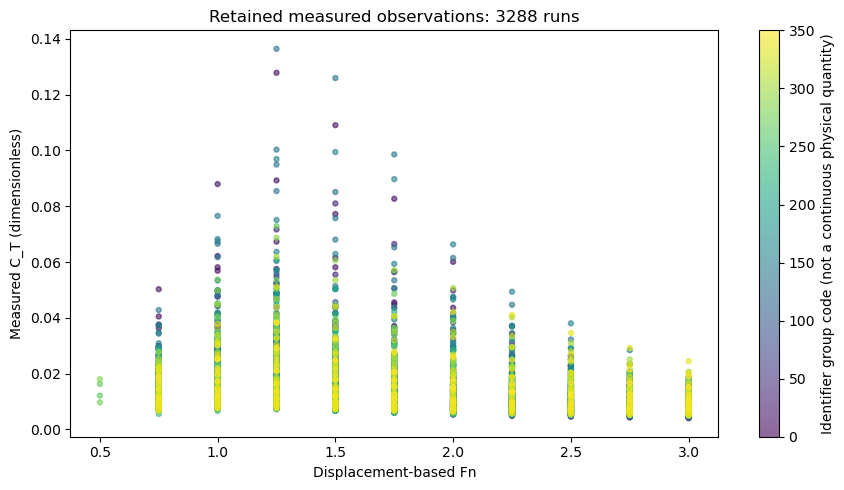

In [2]:
df = pd.read_csv(INPUT)
HULL = ['Beta', 'Lp/Bpx', 'LCG', 'Ap/Nabla^(2/3)', 'Ta', 'Theta_0', 'CAP', 'Nabla_Lp3']
KEY = ['Configuration', 'Model', 'Year']
required = KEY + HULL + ['source_excel_row', 'Fn', 'Re', 'C_T']
missing = sorted(set(required) - set(df.columns))
assert not missing, f'Missing columns: {missing}'
assert len(df) > 0
assert not df[KEY + ['source_excel_row']].isna().any().any()
assert not df['source_excel_row'].duplicated().any()
for col in HULL + ['Fn', 'Re', 'C_T']:
    df[col] = pd.to_numeric(df[col], errors='raise')
assert np.isfinite(df[HULL + ['Fn', 'Re', 'C_T']].to_numpy()).all()
assert (df['Fn'] >= 0.5).all(), 'Prepared-data scope differs from the documented Fn cutoff.'
assert (df['Re'] > 0).all() and (df['C_T'] >= 0).all()
df['analysis_group'] = df.groupby(KEY, sort=True).ngroup()
assert df['analysis_group'].nunique() >= 5
summary = df[HULL + ['Fn', 'Re', 'C_T']].describe().T
summary['missing'] = df[summary.index].isna().sum()
display(pd.DataFrame({'quantity': ['Retained runs', 'Identifier groups'],
                      'count': [len(df), df['analysis_group'].nunique()]}))
display(summary)
summary.to_csv(OUT / 'data_summary.csv', float_format='%.4g')
fig, ax = plt.subplots(figsize=(9, 5))
sc = ax.scatter(df['Fn'], df['C_T'], c=df['analysis_group'], cmap='viridis', s=13, alpha=.6)
ax.set(xlabel='Displacement-based Fn', ylabel='Measured C_T (dimensionless)',
       title=f'Retained measured observations: {len(df)} runs')
fig.colorbar(sc, ax=ax, label='Identifier group code (not a continuous physical quantity)')
fig.tight_layout(); fig.savefig(FIG / 'raw_CT_vs_Fn.png', dpi=160)
plt.show()

## Split
Hold out 20% of identifier groups using `GroupShuffleSplit(random_state=42)`. All runs in a configuration–model–year group stay together. Row fractions need not be 80/20. This is not a temporal split and does not establish transfer to unseen physical hulls if a hull occurs under several identifiers.

Feature forms and model settings are fixed before scoring this split. However, they were informed by prior whole-dataset cross-validation. Do not use the resulting evaluation to claim independent final validation or tune further against it.

In [3]:
splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_GROUP_FRACTION, random_state=SEED)
train_idx, test_idx = next(splitter.split(df, groups=df['analysis_group']))
assert set(df.iloc[train_idx]['analysis_group']).isdisjoint(df.iloc[test_idx]['analysis_group'])
assignments = df[['source_excel_row'] + KEY + ['analysis_group']].copy()
assignments['split'] = 'train'
assignments.loc[test_idx, 'split'] = 'held_out'
assignments.to_csv(OUT / 'split_assignments.csv', index=False)
display(assignments.groupby('split').agg(rows=('source_excel_row', 'size'), groups=('analysis_group', 'nunique')))
# Every group receives equal total weight, regardless of its number of runs.
train = df.iloc[train_idx].copy()
test = df.iloc[test_idx].copy()
y_train = train['C_T'].to_numpy()
y_test = test['C_T'].to_numpy()
train_weight = (1 / train.groupby('analysis_group')['C_T'].transform('size')).to_numpy()
train_weight *= len(train_weight) / train_weight.sum()

,rows,groups
split,,
held_out,672,71
train,2616,280


## Baseline and loss
For error $e=\hat C_T-C_T$, the evaluation loss is $2\max(-e,0)+\max(e,0)$. Average losses within groups, then equally across groups.

The constant baseline is the training-set weighted 2/3 quantile: a constant chosen to minimize this asymmetric absolute loss. Training weights give each group equal total weight. This is a stronger loss-aligned baseline than an arbitrary constant. The factor of two is a provisional preference, not a measured cost ratio.

Both candidates are scored on exactly the same held-out rows. Coefficient error is not a percentage error and is not measured in Newtons.

In [4]:
def weighted_quantile(values, weights, q):
    order = np.argsort(values)
    v, w = np.asarray(values)[order], np.asarray(weights)[order]
    return v[np.searchsorted(np.cumsum(w), q * w.sum(), side='left')]

def score(y, pred, group):
    error = np.asarray(pred) - np.asarray(y)
    rows = pd.DataFrame({'group': np.asarray(group), 'AE': np.abs(error),
                         'asym': UNDER_WEIGHT * np.maximum(-error, 0) + np.maximum(error, 0)})
    by_group = rows.groupby('group')[['AE', 'asym']].mean()
    return {'GroupBalanced_AsymMAE': by_group['asym'].mean(),
            'GroupBalanced_MAE': by_group['AE'].mean(),
            'Pooled_RMSE': np.sqrt(np.mean(error**2)),
            'Pooled_Bias': error.mean(),
            'Underprediction_pct': 100 * np.mean(error < 0)}

constant = weighted_quantile(y_train, train_weight, UNDER_WEIGHT / (1 + UNDER_WEIGHT))
baseline_pred = np.full(len(test), constant)
baseline_score = score(y_test, baseline_pred, test['analysis_group'])
print(f'Training-only constant C_T = {constant:.4g}')
display(pd.DataFrame([baseline_score], index=['Constant baseline']))

Training-only constant C_T = 0.01753


,GroupBalanced_AsymMAE,GroupBalanced_MAE,Pooled_RMSE,Pooled_Bias,Underprediction_pct
Constant baseline,0.01094,0.00816,0.01003,0.003049,23.36


## Model
Use one fixed histogram gradient-boosting regressor. The flow representation is square-root `Fn`, with `Re` omitted, selected as a simple near-leading candidate from the prior flow study. Omitting `Re` is not a claim that viscosity or temperature is irrelevant.

The predictor is $\hat C_T(x)=b+\eta\sum_{m=1}^{300}h_m(x)$, where $h_m$ are fitted regression trees, $b$ is the initial prediction, and $\eta=0.05$ is the learning rate. Inputs are the unchanged hull/static block plus $\sqrt{Fn}$. Trees have at most 15 leaves and require 20 training observations per leaf. L2 regularization is zero.

Training uses unweighted squared error, matching the screening study. Selection/evaluation uses group-balanced asymmetric absolute error. No predicted-trim input, scaling, or clipping is used. The least-trusted assumption is transferability across groups and beyond the observed hull/operating coverage.

In [5]:
def features(frame):
    X = frame[HULL].copy()
    X['sqrt_Fn'] = np.sqrt(frame['Fn'])
    return X

model = HistGradientBoostingRegressor(loss='squared_error', max_iter=300,
    learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=20,
    l2_regularization=0.0, early_stopping=False, random_state=SEED)
model.fit(features(train), y_train)
model_pred = model.predict(features(test))
model_score = score(y_test, model_pred, test['analysis_group'])
results = pd.DataFrame([baseline_score, model_score],
                       index=['Constant baseline', 'Histogram boosting'])
results.index.name = 'Candidate'
display(results)
base = baseline_score['GroupBalanced_AsymMAE']
if base > 0:
    improvement = 100 * (base - model_score['GroupBalanced_AsymMAE']) / base
    print(f'Held-out asymmetric-score improvement over constant baseline: {improvement:.4g}%')
results.to_csv(OUT / 'held_out_scores.csv', float_format='%.4g')
predictions = test[['source_excel_row'] + KEY + ['analysis_group', 'Fn', 'C_T']].copy()
predictions['baseline_CT'] = baseline_pred
predictions['model_CT'] = model_pred
predictions.to_csv(OUT / 'held_out_predictions.csv', index=False, float_format='%.4g')

,GroupBalanced_AsymMAE,GroupBalanced_MAE,Pooled_RMSE,Pooled_Bias,Underprediction_pct
Candidate,,,,,
Constant baseline,0.01094,0.00816,0.01003,0.003049,23.36
Histogram boosting,0.001664,0.001128,0.001953,-4.451e-06,46.28


Held-out asymmetric-score improvement over constant baseline: 84.79%


## Uncertainty and residual checks
Bootstrap held-out groups to summarize variability of the **paired score improvement**, conditional on the fitted models and this split. The interval does not account for prior feature selection, training-set variability, or domain shift. It is not an individual prediction interval. Few held-out groups make this estimate unstable; individual predictive uncertainty remains uncalibrated.

Paired loss reduction (C_T units): 0.009275; group-bootstrap 95% interval [0.0074, 0.01152]
Held-out groups: 71. Interval is conditional, not final validation.


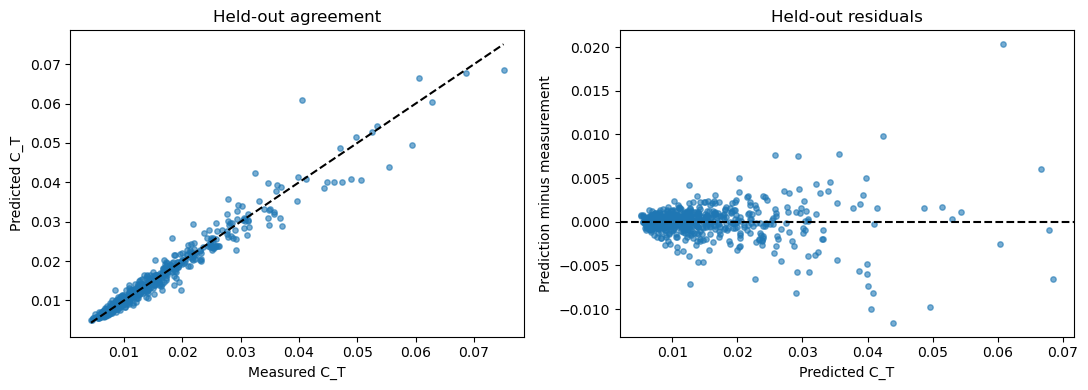

Negative model predictions (%): 0


In [6]:
err = model_pred - y_test
loss_base = UNDER_WEIGHT * np.maximum(y_test - baseline_pred, 0) + np.maximum(baseline_pred - y_test, 0)
loss_model = UNDER_WEIGHT * np.maximum(-err, 0) + np.maximum(err, 0)
paired = pd.DataFrame({'group': test['analysis_group'].to_numpy(),
                       'baseline': loss_base, 'model': loss_model}).groupby('group').mean()
gain = (paired['baseline'] - paired['model']).to_numpy()
rng = np.random.default_rng(SEED)
boot = np.array([rng.choice(gain, size=len(gain), replace=True).mean() for _ in range(2000)])
ci = np.quantile(boot, [.025, .975])
print(f'Paired loss reduction (C_T units): {gain.mean():.4g}; group-bootstrap 95% interval [{ci[0]:.4g}, {ci[1]:.4g}]')
print(f'Held-out groups: {len(gain)}. Interval is conditional, not final validation.')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, model_pred, s=15, alpha=.6)
lo, hi = min(y_test.min(), model_pred.min()), max(y_test.max(), model_pred.max())
axes[0].plot([lo, hi], [lo, hi], 'k--')
axes[0].set(xlabel='Measured C_T', ylabel='Predicted C_T', title='Held-out agreement')
axes[1].scatter(model_pred, err, s=15, alpha=.6)
axes[1].axhline(0, color='k', linestyle='--')
axes[1].set(xlabel='Predicted C_T', ylabel='Prediction minus measurement', title='Held-out residuals')
fig.tight_layout(); fig.savefig(FIG / 'held_out_diagnostics.png', dpi=160)
plt.show()
print('Negative model predictions (%):', f'{100*np.mean(model_pred < 0):.4g}')

## Simulation check — scope
A tree ensemble does not estimate unique physical coefficients to recover. A parameter-recovery claim is therefore not made. A dedicated synthetic-response recovery experiment remains future work if required by the final checklist; it is not substituted by a good held-out score.

## Decision
The preliminary action is to retain the fixed candidate for further hull-representation study only if its held-out group-balanced asymmetric loss is lower than the constant baseline. This is a development gate, not an operational design approval. Do not silently switch models after viewing this evaluation.

The product is a coefficient estimate with an explicit underprediction preference, not a guaranteed conservative bound. A lower coefficient prediction for a hull is not, on its own, a verified lower resistance force: the current coefficient uses running wetted area.

## Limits and next analysis
- Prior whole-dataset flow selection prevents an untouched-final-test claim.
- Grouping may not isolate physical hulls, and is not a temporal split.
- No extrapolation or calibrated individual-interval guarantee is provided.
- Static wetted area, running trim, and dZ models are not part of this preliminary comparison.
- Next: controlled hull/static-block ablations, followed by a small flow–hull confirmation. Keep final evaluation separate from that search.

The presentation must quote the executed notebook scores and units, not substitute the earlier best-of-288 scores.

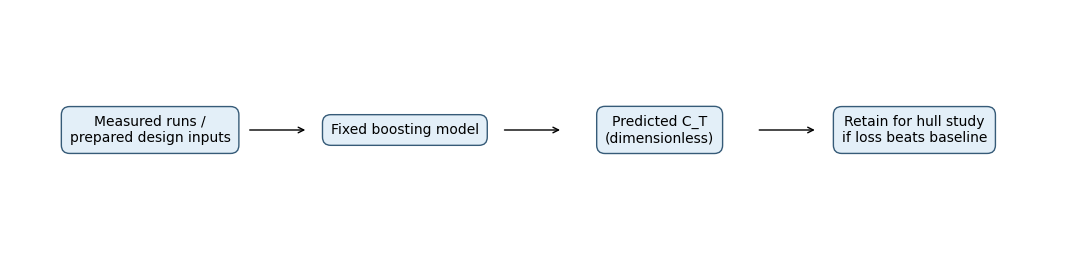

Notebook complete. Copy executed held-out results into the presentation.


In [7]:
fig, ax = plt.subplots(figsize=(11, 2.7))
labels = ['Measured runs /\nprepared design inputs', 'Fixed boosting model', 'Predicted C_T\n(dimensionless)', 'Retain for hull study\nif loss beats baseline']
for i, label in enumerate(labels):
    ax.text(i, .5, label, ha='center', va='center', fontsize=10,
            bbox={'boxstyle': 'round,pad=.6', 'facecolor': '#e3eff8', 'edgecolor': '#365b78'})
    if i < 3:
        ax.annotate('', xy=(i+.62,.5), xytext=(i+.38,.5), arrowprops={'arrowstyle': '->'})
ax.set(xlim=(-.55,3.65), ylim=(0,1)); ax.axis('off')
fig.tight_layout(); fig.savefig(FIG / 'layers.png', dpi=160); plt.show()
print('Notebook complete. Copy executed held-out results into the presentation.')